# 03 · TF-IDF & BM25 — the keyword-search baseline
**Owner:** Laiba Shaikh · **Proposal model #1:** *TF-IDF + cosine similarity (traditional IR baseline)*. I also add BM25 as a stronger keyword reference.

**Protocol (no leakage):** hyper-parameters are chosen on the **train** claims; the **dev** claims are touched once, to report. Test claims are unlabeled.

In [ ]:
import sys, json, itertools, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from retrieval.data import load_corpus, load_claims, build_qrels
from retrieval.sparse import TfidfRetriever, BM25Retriever, TFIDF_PARAMS, BM25_PARAMS
from retrieval.evaluate import evaluate_run, save_run, save_metrics, per_query_first_hit_rank
FIG = ROOT / "results" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

corpus = load_corpus()
ids, texts = [d["id"] for d in corpus], [d["text"] for d in corpus]
def split(name):
    cl = load_claims(name); qr = build_qrels(cl)
    return {str(c["id"]): c["claim"] for c in cl if str(c["id"]) in qr}, qr
q_tr, qrels_tr = split("train"); q_dv, qrels_dv = split("dev")
print("train queries:", len(q_tr), "| dev queries:", len(q_dv), "| docs:", len(ids))

train queries: 505 | dev queries: 188 | docs: 5183


## 1 · Tune TF-IDF on train

In [ ]:
rows = []
for sw, ng, sub, mdf in itertools.product(["english", None], [(1, 1), (1, 2)], [True, False], [1, 2]):
    r = TfidfRetriever(ids, texts, stop_words=sw, ngram_range=ng, sublinear_tf=sub, min_df=mdf)
    m = evaluate_run(r.run(q_tr, 100), qrels_tr)
    rows.append({"stop_words": sw, "ngram": ng, "sublinear_tf": sub, "min_df": mdf,
                 "nDCG@10": m["nDCG@10"], "Recall@10": m["Recall@10"], "Recall@100": m["Recall@100"]})
grid = pd.DataFrame(rows).sort_values("nDCG@10", ascending=False).reset_index(drop=True)
print(grid.round(4).to_string())
best_tfidf = {k: grid.loc[0, k] for k in ["stop_words", "ngram", "sublinear_tf", "min_df"]}
best_tfidf = {"stop_words": None if pd.isna(best_tfidf["stop_words"]) else best_tfidf["stop_words"],
              "ngram": tuple(best_tfidf["ngram"]), "sublinear_tf": bool(best_tfidf["sublinear_tf"]), "min_df": int(best_tfidf["min_df"])}
print("\nBEST TF-IDF (train):", best_tfidf)

   stop_words   ngram  sublinear_tf  min_df  nDCG@10  Recall@10  Recall@100
0         NaN  (1, 1)          True       1   0.8093     0.9201      0.9777
1     english  (1, 1)          True       1   0.8078     0.9208      0.9748
2     english  (1, 2)          True       1   0.7837     0.9071      0.9728
3         NaN  (1, 2)          True       1   0.7724     0.8917      0.9698
4         NaN  (1, 2)         False       1   0.7568     0.8965      0.9678
5     english  (1, 2)         False       1   0.7561     0.8911      0.9748
6         NaN  (1, 1)          True       2   0.7515     0.8870      0.9668
7     english  (1, 1)          True       2   0.7507     0.8876      0.9688
8         NaN  (1, 1)         False       1   0.7507     0.8881      0.9718
9     english  (1, 1)         False       1   0.7503     0.8921      0.9711
10        NaN  (1, 2)          True       2   0.7267     0.8640      0.9599
11    english  (1, 2)          True       2   0.7202     0.8640      0.9639
12        Na

**Reading the grid:**
* **Sublinear TF** (log-scaling term counts) is the biggest win: 0.809 vs 0.751 nDCG@10 with everything else equal.
* **`min_df=2` is clearly harmful** (≈ −0.06): dropping terms that occur in only one abstract throws away exactly the rare, highly specific terms (gene/drug names) that identify a paper.
* **Bigrams hurt** here; a plausible reason is that they add many sparse features that dilute the signal from single rare terms (not tested directly).
* Stop-word removal is a near-tie (≈ 0.0015 apart), so the choice between the top two rows is not meaningful.

## 2 · Tune BM25 on train

In [ ]:
rows = []
for k1, b, sw in itertools.product([0.6, 0.9, 1.2, 1.5, 2.0], [0.3, 0.5, 0.75, 0.9], ["english", None]):
    r = BM25Retriever(ids, texts, k1=k1, b=b, stop_words=sw)
    m = evaluate_run(r.run(q_tr, 100), qrels_tr)
    rows.append({"k1": k1, "b": b, "stop_words": sw, "nDCG@10": m["nDCG@10"], "Recall@100": m["Recall@100"]})
bgrid = pd.DataFrame(rows).sort_values("nDCG@10", ascending=False).reset_index(drop=True)
print(bgrid.head(8).round(4).to_string())
best_bm25 = bgrid.loc[0, ["k1", "b"]].to_dict(); best_bm25_sw = bgrid.loc[0, "stop_words"]
print("\nBEST BM25 (train): k1 =", best_bm25["k1"], " b =", best_bm25["b"], " stop_words =", best_bm25_sw)

# guard: the constants the API uses (retrieval/sparse.py) must equal what this notebook derived
assert TFIDF_PARAMS["stop_words"] == best_tfidf["stop_words"] and TFIDF_PARAMS["sublinear_tf"] == best_tfidf["sublinear_tf"]
assert TFIDF_PARAMS["ngram_range"] == best_tfidf["ngram"] and TFIDF_PARAMS["min_df"] == best_tfidf["min_df"]
assert (BM25_PARAMS["k1"], BM25_PARAMS["b"], BM25_PARAMS["stop_words"]) == (best_bm25["k1"], best_bm25["b"], best_bm25_sw)
print("API defaults in retrieval/sparse.py match the tuned values")

    k1     b stop_words  nDCG@10  Recall@100
0  0.9  0.50    english   0.8403      0.9728
1  1.2  0.50        NaN   0.8386      0.9738
2  0.9  0.75        NaN   0.8383      0.9738
3  1.2  0.75        NaN   0.8379      0.9738
4  0.9  0.50        NaN   0.8377      0.9718
5  0.6  0.75    english   0.8372      0.9728
6  1.2  0.50    english   0.8369      0.9728
7  1.2  0.30    english   0.8367      0.9708

BEST BM25 (train): k1 = 0.9  b = 0.5  stop_words = english
API defaults in retrieval/sparse.py match the tuned values


## 3 · Report on dev (touched once)

In [ ]:
systems = {
    "tfidf_default_sklearn": TfidfRetriever(ids, texts, stop_words=None, ngram_range=(1, 1), sublinear_tf=False, min_df=1),
    "tfidf": TfidfRetriever(ids, texts),          # tuned  (== TFIDF_PARAMS)
    "bm25": BM25Retriever(ids, texts),            # tuned  (== BM25_PARAMS)
}
runs, results = {}, {}
for name, r in systems.items():
    t0 = time.time(); runs[name] = r.run(q_dv, 100); dt = time.time() - t0
    results[name] = evaluate_run(runs[name], qrels_dv)
    results[name]["ms_per_query"] = 1000 * dt / len(q_dv)
cols = ["Recall@1", "Recall@5", "Recall@10", "Recall@20", "Recall@100", "MRR@10", "nDCG@10", "MAP", "ms_per_query"]
table = pd.DataFrame(results).T[cols]
print(table.round(3).to_string())

# persist for the evaluation notebook (06) and for the final report
for name in ["tfidf", "bm25"]:
    save_run(name, "dev", runs[name])
cfg = {"tfidf": {k: str(v) for k, v in TFIDF_PARAMS.items()}, "bm25": {k: str(v) for k, v in BM25_PARAMS.items()}}
for name in ["tfidf", "bm25"]:
    save_metrics(name, "dev", {**results[name], "config": cfg[name]})
print("\nsaved runs + metrics for:", ["tfidf", "bm25"])

                       Recall@1  Recall@5  Recall@10  Recall@20  Recall@100  MRR@10  nDCG@10    MAP  ms_per_query
tfidf_default_sklearn     0.565     0.801      0.844      0.898       0.966   0.677    0.712  0.671         0.268
tfidf                     0.621     0.876      0.910      0.939       0.967   0.736    0.772  0.726         0.223
bm25                      0.696     0.857      0.924      0.943       0.959   0.785    0.815  0.779         0.123

saved runs + metrics for: ['tfidf', 'bm25']


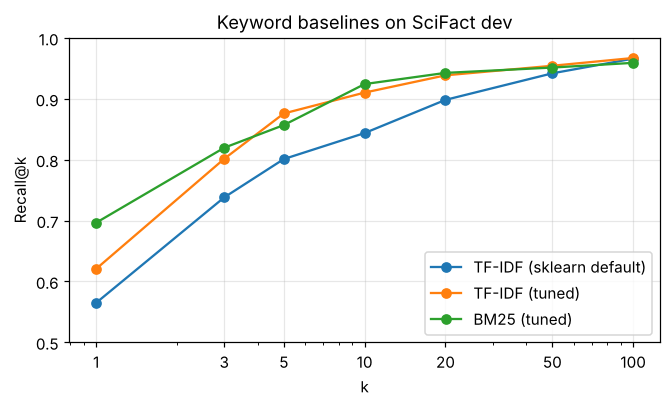

In [ ]:
ks = [1, 3, 5, 10, 20, 50, 100]
fig, ax = plt.subplots(figsize=(6.2, 3.8))
for name, label in [("tfidf_default_sklearn", "TF-IDF (sklearn default)"), ("tfidf", "TF-IDF (tuned)"), ("bm25", "BM25 (tuned)")]:
    cur = evaluate_run(runs[name], qrels_dv, ks=ks)
    ax.plot(ks, [cur[f"Recall@{k}"] for k in ks], marker="o", label=label)
ax.set(xscale="log", xlabel="k", ylabel="Recall@k", title="Keyword baselines on SciFact dev", ylim=(0.5, 1.0))
ax.set_xticks(ks); ax.set_xticklabels(ks); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "03_sparse_recall_curve.png", dpi=130); plt.show()

## 4 · Error analysis — where does keyword search fail?

In [ ]:
rank_b = per_query_first_hit_rank(runs["bm25"], qrels_dv)
rank_t = per_query_first_hit_rank(runs["tfidf"], qrels_dv)
failed = [q for q, r in rank_b.items() if r is None or r > 10]
print(f"BM25 misses the relevant abstract in the top 10 for {len(failed)} / {len(rank_b)} dev claims\n")
dv_claims = {str(c["id"]): c["claim"] for c in load_claims("dev")}
by_id = {d["id"]: d for d in corpus}
for q in failed[:6]:
    gold = sorted(qrels_dv[q])[0]
    print(f"[{q}] rank of gold = {rank_b[q] or 'not in top-100'}  |  CLAIM: {dv_claims[q]}")
    print(f"      GOLD TITLE: {by_id[gold]['title']}\n")

BM25 misses the relevant abstract in the top 10 for 12 / 188 dev claims

[239] rank of gold = not in top-100  |  CLAIM: Cellular aging closely links to an older appearance.
      GOLD TITLE: Perceived age as clinically useful biomarker of ageing: cohort study.

[431] rank of gold = not in top-100  |  CLAIM: FoxO3a activation in neuronal death is mediated by reactive oxygen species (ROS).
      GOLD TITLE: Stress-dependent regulation of FOXO transcription factors by the SIRT1 deacetylase.

[475] rank of gold = 12  |  CLAIM: Glycolysis is one of the primary glycometabolic pathways in cells.
      GOLD TITLE: Vesicular Glycolysis Provides On-Board Energy for Fast Axonal Transport

[756] rank of gold = 11  |  CLAIM: Many proteins in human cells can be post-translationally modified at lysine residues via acetylation.
      GOLD TITLE: Protein Lysine Acetylated/Deacetylated Enzymes and the Metabolism-Related Diseases

[873] rank of gold = 14  |  CLAIM: Obesity is determined solely by environ

In [ ]:
only_bm25 = [q for q in rank_b if (rank_b[q] or 999) <= 10 < (rank_t[q] or 999)]
only_tfidf = [q for q in rank_b if (rank_t[q] or 999) <= 10 < (rank_b[q] or 999)]
print("rescued by BM25 but missed by TF-IDF (top-10):", len(only_bm25), "| the reverse:", len(only_tfidf))
easy = sum(1 for r in rank_b.values() if r == 1)
print(f"BM25 ranks the gold abstract FIRST for {easy} / {len(rank_b)} dev claims ({easy/len(rank_b):.0%})")

rescued by BM25 but missed by TF-IDF (top-10): 5 | the reverse: 3
BM25 ranks the gold abstract FIRST for 134 / 188 dev claims (71%)


## 5 · Takeaways for the comparison with dense retrieval
* The keyword baseline is **strong** on SciFact (BM25 puts the gold abstract first for ~70% of dev claims), presumably because claims reuse specific terms from the abstract they relate to.
  Dense models therefore have to beat a *tuned* baseline, not a straw man. Tuning matters a lot: sklearn-default TF-IDF 0.712 → tuned TF-IDF 0.772 → tuned BM25 0.815 nDCG@10.
* In the failures printed above, claim and abstract often use different wording or a more general/specific concept (e.g. "cellular aging" vs "perceived age"), which looks like vocabulary mismatch — the case semantic embeddings are meant to help with. This is an impression from a handful of examples, not a measured breakdown; notebooks 04–05 test whether dense models actually do better.
* Saved: `results/runs/{tfidf,bm25}_dev.json` (top-100 ranking per dev claim) and `results/metrics/*_dev.json` — the evaluation notebook (06) can load these directly.